# Análise exploratória — Online Shoppers Purchasing Intention

**Objetivo:** entender a estrutura e a qualidade dos dados antes de construir as camadas
Bronze, Silver e Gold, e registrar as decisões de preparação com justificativa.

- **Fonte:** [UCI Machine Learning Repository — dataset 468](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- **Arquivo:** `data/raw/online_shoppers_intention.csv`
- **Alvo:** `Revenue` (a sessão terminou em compra?)

Cada linha representa uma **sessão** de um usuário diferente ao longo de um ano.

In [40]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# O VS Code executa o notebook a partir da pasta notebooks/; subimos um nível
# para que os caminhos funcionem tanto daqui quanto da raiz do projeto.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "online_shoppers_intention.csv"
EXPECTED_SHA256 = "b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9"

# Paleta enxuta: azul para a série principal, laranja apenas para destacar compras.
PRIMARY_COLOR = "#2a78d6"
HIGHLIGHT_COLOR = "#eb6834"
SECONDARY_TEXT_COLOR = "#52514e"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": SECONDARY_TEXT_COLOR,
        "axes.labelcolor": SECONDARY_TEXT_COLOR,
        "xtick.color": SECONDARY_TEXT_COLOR,
        "ytick.color": SECONDARY_TEXT_COLOR,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
    }
)

## 1. Integridade e estrutura

Antes de qualquer análise, conferimos se o arquivo é exatamente o publicado pela UCI.

In [41]:
computed_sha256 = hashlib.sha256(RAW_CSV_PATH.read_bytes()).hexdigest()
print("SHA-256 confere:", computed_sha256 == EXPECTED_SHA256)

sessions = pd.read_csv(RAW_CSV_PATH)
print("Linhas x colunas:", sessions.shape)
sessions.head()

SHA-256 confere: True
Linhas x colunas: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [42]:
sessions.dtypes.to_frame("tipo")

,tipo
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


## 2. Variável-alvo e desbalanceamento

,sessões,proporção
Revenue,,
False,10422,0.8453
True,1908,0.1547


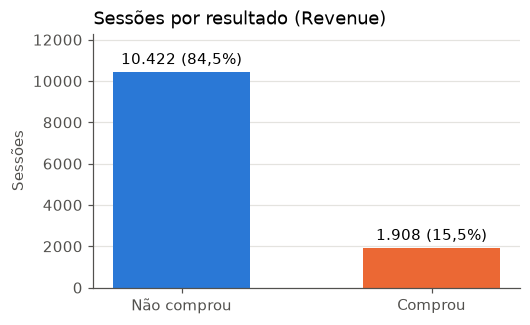

In [43]:
target_counts = sessions["Revenue"].value_counts()
target_share = sessions["Revenue"].value_counts(normalize=True)
display(pd.DataFrame({"sessões": target_counts, "proporção": target_share.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3))
labels = ["Não comprou", "Comprou"]
values = [target_counts[False], target_counts[True]]
bars = ax.bar(labels, values, color=[PRIMARY_COLOR, HIGHLIGHT_COLOR], width=0.55)
total = sum(values)
# Rótulos no padrão brasileiro: ponto como separador de milhar, vírgula decimal.
bar_labels = [
    f"{v:,} ({v / total:.1%})".replace(",", "X").replace(".", ",").replace("X", ".")
    for v in values
]
ax.bar_label(bars, labels=bar_labels, padding=3)
ax.set_ylim(0, max(values) * 1.18)  # folga para o rótulo não encostar no título
ax.set_title("Sessões por resultado (Revenue)", loc="left")
ax.set_ylabel("Sessões")
plt.show()

## 3. Valores ausentes

In [44]:
missing_values = sessions.isna().sum()
print("Total de valores ausentes:", int(missing_values.sum()))

Total de valores ausentes: 0


## 4. Registros duplicados

O dataset não tem identificador de sessão, então linhas idênticas podem ser
**erros de coleta** ou **sessões legítimas** com comportamento idêntico.
Investigamos o perfil das duplicatas para decidir.

In [45]:
duplicated_mask = sessions.duplicated()
duplicates = sessions[duplicated_mask]
print("Linhas duplicadas (exceto a primeira ocorrência):", len(duplicates))
print("Proporção do dataset:", f"{len(duplicates) / len(sessions):.2%}")
print("Revenue nas duplicadas:", duplicates["Revenue"].value_counts().to_dict())

# Mesmas features com alvos diferentes indicariam ruído de rótulo.
features = sessions.columns.drop("Revenue")
conflicting = sessions.duplicated(subset=features, keep=False) & ~sessions.duplicated(
    keep=False
)
print("Sessões com mesmas features e alvo diferente:", int(conflicting.sum()))

Linhas duplicadas (exceto a primeira ocorrência): 125
Proporção do dataset: 1.01%
Revenue nas duplicadas: {False: 125}
Sessões com mesmas features e alvo diferente: 0


In [46]:
# Agrupa as cópias idênticas para ver se são poucos blocos repetidos (indício de
# erro de coleta) ou muitos grupos pequenos e espalhados (coincidência natural).
all_copies = sessions[sessions.duplicated(keep=False)]
group_sizes = all_copies.groupby(list(sessions.columns)).size()
print("Grupos distintos:", len(group_sizes), "| maior grupo:", group_sizes.max())
print(
    "Variedade nas cópias -> meses:",
    all_copies["Month"].nunique(),
    "| regiões:",
    all_copies["Region"].nunique(),
    "| tipos de tráfego:",
    all_copies["TrafficType"].nunique(),
)

Grupos distintos: 76 | maior grupo: 14
Variedade nas cópias -> meses: 6 | regiões: 8 | tipos de tráfego: 9


In [47]:
behavior_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
]
duplicates[behavior_columns].describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
Administrative,0.00,0.0,0.0
Administrative_Duration,0.00,0.0,0.0
Informational,0.00,0.0,0.0
Informational_Duration,0.00,0.0,0.0
ProductRelated,1.06,1.0,2.0
ProductRelated_Duration,0.00,0.0,0.0
BounceRates,0.20,0.2,0.2
ExitRates,0.20,0.2,0.2
PageValues,0.00,0.0,0.0


**Leitura:** todas as duplicatas são sessões de **rejeição** (*bounce*): no máximo duas páginas
de produto, duração zero, `BounceRates` e `ExitRates` iguais a 0,2 e nenhuma compra.
Formam dezenas de grupos pequenos, espalhados por meses, regiões e tipos de tráfego,
e não um bloco repetido. São as sessões com menos informação possível, por isso é
natural que se repitam de forma idêntica entre usuários diferentes.

**Decisão:** manter as duplicatas e registrar a quantidade a cada execução da camada Silver.

## 5. Variáveis categóricas

In [48]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(
    "Meses presentes:", sessions["Month"].value_counts().reindex(month_order).to_dict()
)
print("VisitorType:", sessions["VisitorType"].value_counts().to_dict())
print("Weekend:", sessions["Weekend"].unique().tolist())

# Estas colunas são inteiras, mas cada número é um código de categoria
# (ex.: Browser=2 não é "o dobro" de Browser=1).
for column in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    frequencies = sessions[column].value_counts()
    rare_codes = frequencies[frequencies < 50]
    print(
        f"{column}: {sessions[column].nunique()} códigos, {len(rare_codes)} raros (<50)"
    )

Meses presentes: {'Feb': 184, 'Mar': 1907, 'May': 3364, 'June': 288, 'Jul': 432, 'Aug': 433, 'Sep': 448, 'Oct': 549, 'Nov': 2998, 'Dec': 1727}
VisitorType: {'Returning_Visitor': 10551, 'New_Visitor': 1694, 'Other': 85}
Weekend: [False, True]
OperatingSystems: 8 códigos, 3 raros (<50)
Browser: 13 códigos, 4 raros (<50)
Region: 9 códigos, 0 raros (<50)
TrafficType: 20 códigos, 9 raros (<50)


**Inconsistências encontradas em `Month`:**
- Junho aparece como `"June"`, enquanto os demais meses usam três letras (`"Jul"`, `"Aug"`...).
- **Janeiro e abril não existem** no dataset. O modelo precisa tolerar meses nunca vistos.

## 6. Variáveis numéricas

In [49]:
numeric_columns = behavior_columns + ["SpecialDay"]
summary = sessions[numeric_columns].describe().T[["min", "50%", "mean", "max"]]
summary["assimetria"] = sessions[numeric_columns].skew()
print("Valores negativos:", int((sessions[numeric_columns] < 0).sum().sum()))
summary.round(2)

Valores negativos: 0


,min,50%,mean,max,assimetria
Administrative,0.0,1.00,2.32,27.00,1.96
Administrative_Duration,0.0,7.50,80.82,3398.75,5.62
Informational,0.0,0.00,0.50,24.00,4.04
Informational_Duration,0.0,0.00,34.47,2549.38,7.58
ProductRelated,0.0,18.00,31.73,705.00,4.34
ProductRelated_Duration,0.0,598.94,1194.75,63973.52,7.26
BounceRates,0.0,0.00,0.02,0.20,2.95
ExitRates,0.0,0.03,0.04,0.20,2.15
PageValues,0.0,0.00,5.89,361.76,6.38
SpecialDay,0.0,0.00,0.06,1.00,3.30


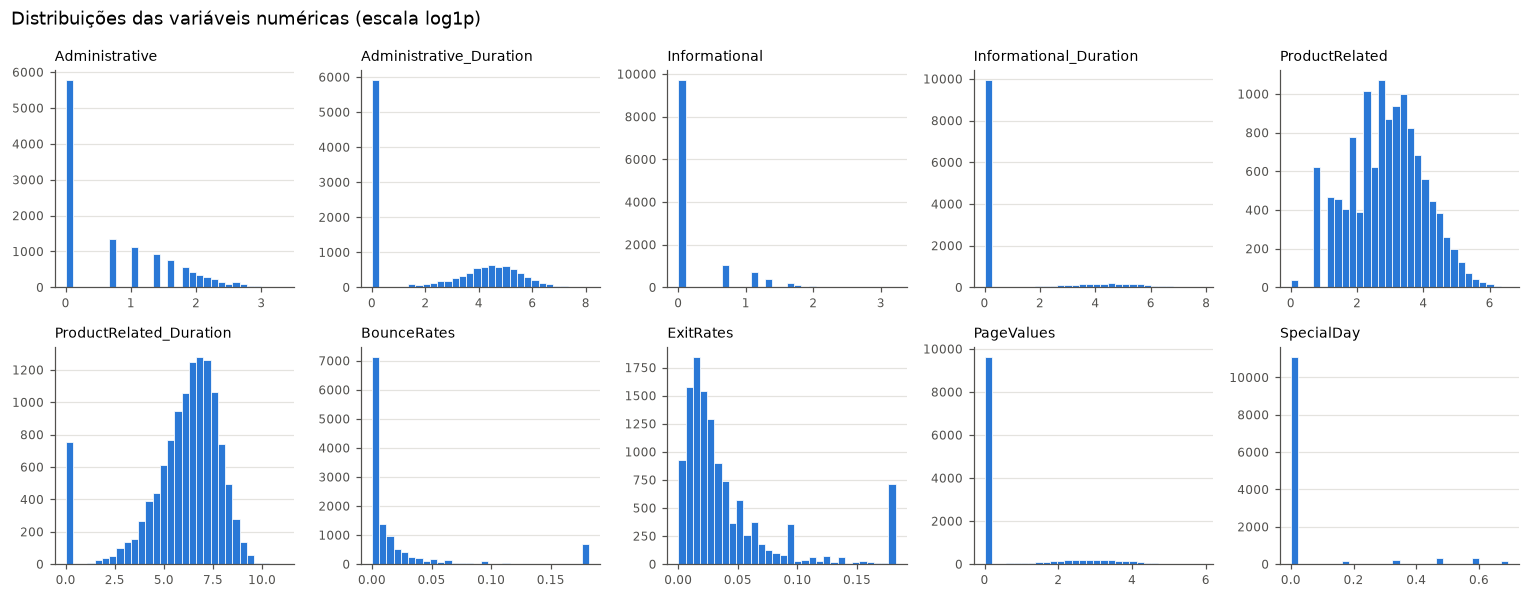

In [50]:
# Escala log1p apenas para visualizar: as distribuições originais são muito
# concentradas em zero, com caudas longas.
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5))
for ax, column in zip(axes.flat, numeric_columns, strict=True):
    ax.hist(
        np.log1p(sessions[column]),
        bins=30,
        color=PRIMARY_COLOR,
        edgecolor="white",
        linewidth=0.5,
    )
    ax.set_title(column, fontsize=9, loc="left")
    ax.tick_params(labelsize=8)
fig.suptitle("Distribuições das variáveis numéricas (escala log1p)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 7. Relação com a variável-alvo

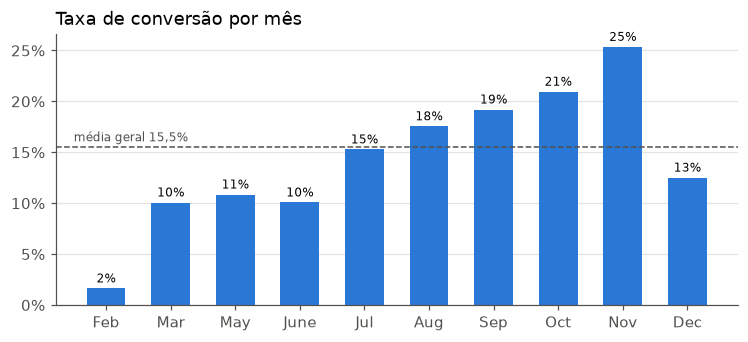

In [51]:
overall_rate = sessions["Revenue"].mean()
rate_by_month = sessions.groupby("Month")["Revenue"].mean().reindex(month_order)

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(rate_by_month.index, rate_by_month.values, color=PRIMARY_COLOR, width=0.6)
ax.bar_label(
    bars, labels=[f"{r:.0%}" for r in rate_by_month.values], padding=2, fontsize=8
)
ax.axhline(overall_rate, color=SECONDARY_TEXT_COLOR, linestyle="--", linewidth=1)
# Anotação à esquerda, sobre fevereiro, onde a barra é baixa e não há colisão.
ax.annotate(
    f"média geral {overall_rate:.1%}".replace(".", ","),
    xy=(-0.5, overall_rate),
    xytext=(0, 4),
    textcoords="offset points",
    ha="left",
    fontsize=8,
    color=SECONDARY_TEXT_COLOR,
)
ax.set_title("Taxa de conversão por mês", loc="left")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.show()

In [52]:
conversion_by_page_value = (
    sessions.assign(visited_valued_page=sessions["PageValues"] > 0)
    .groupby("visited_valued_page")["Revenue"]
    .agg(sessions="size", conversion_rate="mean")
)
conversion_by_page_value.round(3)

,sessions,conversion_rate
visited_valued_page,,
False,9600,0.039
True,2730,0.563


In [53]:
sessions.groupby("VisitorType")["Revenue"].agg(
    sessions="size", conversion_rate="mean"
).round(3)

,sessions,conversion_rate
VisitorType,,
New_Visitor,1694,0.249
Other,85,0.188
Returning_Visitor,10551,0.139


**Leitura:** `PageValues` é o sinal mais forte: sessões que passaram por páginas com valor
convertem **56%**, contra **4%** das demais.

O Google Analytics dá a cada página uma "nota" conforme ela aparece no caminho de quem compra:
o valor de cada compra é distribuído entre as páginas visitadas **antes** dela. `PageValues` é a
média das notas das páginas que a sessão visitou. Ou seja, a nota é construída **a partir das
próprias compras**, e páginas como carrinho e pagamento ganham nota alta porque quase todo
mundo que passa por elas compra.

Mantemos a variável porque ela existe durante a navegação e é usada no artigo original do
dataset (Sakar et al., 2019). Registramos como **limitação**: em produção, as notas das páginas
precisam ser calculadas com compras de **outras sessões, do passado**, e nunca com a compra da
própria sessão que se quer prever.

## 8. Conclusões e decisões para as camadas

| # | Achado | Decisão | Camada |
|---|---|---|---|
| 1 | Arquivo íntegro (SHA-256 confere), 12.330 × 18 | Registrar origem e hash nos metadados | Bronze |
| 2 | Nenhum valor ausente, nenhum valor negativo | Validar essas regras no schema, falhando se mudarem | Silver |
| 3 | 125 duplicatas (1,01%), todas sessões de rejeição sem compra | **Manter** — são sessões legítimas e idênticas por terem pouca informação; removê-las distorceria a proporção real de rejeições. A quantidade é registrada a cada execução. | Silver |
| 4 | `Month` com `"June"` fora do padrão | Padronizar para `"Jun"` | Silver |
| 5 | Janeiro e abril ausentes | `OneHotEncoder(handle_unknown="ignore")` | Pipeline do modelo |
| 6 | `OperatingSystems`, `Browser`, `Region`, `TrafficType` são códigos | Tratar como **categóricas** | Silver + pipeline |
| 7 | `Weekend` e `Revenue` booleanos | Manter booleanos; alvo convertido para 0/1 | Silver / Gold |
| 8 | Numéricas muito assimétricas (assimetria até 7,6) | `log1p` + `StandardScaler` **dentro do Pipeline**, ajustados só no treino | Pipeline do modelo |
| 9 | Classe positiva com 15,5% | Split estratificado, `class_weight="balanced"`, seleção por F1 na CV | Gold + modelagem |
| 10 | `PageValues` muito preditiva e construída a partir das compras | Manter e documentar como limitação | README |

Nenhuma transformação que aprende parâmetros (média, desvio, categorias) acontece antes do split.